In [6]:
import pandas as pd
import numpy as np

ogrenci_sayisi = 50

veri = {
    "StudentId": range(1, ogrenci_sayisi + 1), 
    "Name": [f"Öğrenci {i}" for i in range(1, ogrenci_sayisi + 1)],
    "Age": np.random.randint(18, 26, ogrenci_sayisi), 
    "Gender": np.random.choice(["Kadın", "Erkek"], ogrenci_sayisi), 
    "MathScore": np.random.randint(0, 101, ogrenci_sayisi),
    "PhysicsScore": np.random.randint(0, 101, ogrenci_sayisi),
    "ProgrammingScore": np.random.randint(0, 101, ogrenci_sayisi),
    "StudyHours": np.random.randint(1, 11, ogrenci_sayisi),
    "Attendance": np.random.randint(50, 101, ogrenci_sayisi)
    
}

df = pd.DataFrame(veri)
df.to_csv('ogrenci_sinav_analizi.csv', index=False)
df

,StudentId,Name,Age,Gender,MathScore,PhysicsScore,ProgrammingScore,StudyHours,Attendance
0,1,Öğrenci 1,18,Kadın,15,54,58,10,98
1,2,Öğrenci 2,22,Erkek,31,31,39,4,61
2,3,Öğrenci 3,24,Kadın,92,10,73,9,62
3,4,Öğrenci 4,22,Kadın,15,98,11,8,67
4,5,Öğrenci 5,25,Erkek,57,82,46,6,76
5,6,Öğrenci 6,22,Erkek,4,37,25,6,87
6,7,Öğrenci 7,20,Kadın,52,48,70,4,69
7,8,Öğrenci 8,20,Kadın,41,45,25,5,71
8,9,Öğrenci 9,20,Kadın,64,67,55,10,57
9,10,Öğrenci 10,18,Erkek,3,29,1,7,75


In [7]:
df = pd.read_csv('ogrenci_sinav_analizi.csv')

In [8]:
df.head()

,StudentId,Name,Age,Gender,MathScore,PhysicsScore,ProgrammingScore,StudyHours,Attendance
0,1,Öğrenci 1,18,Kadın,15,54,58,10,98
1,2,Öğrenci 2,22,Erkek,31,31,39,4,61
2,3,Öğrenci 3,24,Kadın,92,10,73,9,62
3,4,Öğrenci 4,22,Kadın,15,98,11,8,67
4,5,Öğrenci 5,25,Erkek,57,82,46,6,76


In [9]:
df.shape

(50, 9)

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   StudentId         50 non-null     int64
 1   Name              50 non-null     str  
 2   Age               50 non-null     int64
 3   Gender            50 non-null     str  
 4   MathScore         50 non-null     int64
 5   PhysicsScore      50 non-null     int64
 6   ProgrammingScore  50 non-null     int64
 7   StudyHours        50 non-null     int64
 8   Attendance        50 non-null     int64
dtypes: int64(7), str(2)
memory usage: 3.6 KB


In [13]:
df.describe()

,StudentId,Age,MathScore,PhysicsScore,ProgrammingScore,StudyHours,Attendance
count,50.00000,50.000000,50.00000,50.000000,50.000000,50.000000,50.000000
mean,25.50000,22.060000,41.04000,48.020000,47.600000,5.840000,76.680000
std,14.57738,2.244358,29.03338,29.666507,30.775686,2.772754,15.332292
min,1.00000,18.000000,2.00000,2.000000,1.000000,1.000000,51.000000
25%,13.25000,20.000000,15.00000,24.500000,25.000000,4.000000,64.500000
50%,25.50000,22.000000,41.00000,47.500000,41.500000,6.000000,75.500000
75%,37.75000,24.000000,64.00000,71.750000,73.750000,8.000000,91.750000
max,50.00000,25.000000,97.00000,99.000000,99.000000,10.000000,100.000000


In [14]:
df["AverageScore"] = (df["MathScore"] + df["PhysicsScore"] + df["ProgrammingScore"]) / 3

In [17]:
df.head()

,StudentId,Name,Age,Gender,MathScore,PhysicsScore,ProgrammingScore,StudyHours,Attendance,AverageScore
0,1,Öğrenci 1,18,Kadın,15,54,58,10,98,42.333333
1,2,Öğrenci 2,22,Erkek,31,31,39,4,61,33.666667
2,3,Öğrenci 3,24,Kadın,92,10,73,9,62,58.333333
3,4,Öğrenci 4,22,Kadın,15,98,11,8,67,41.333333
4,5,Öğrenci 5,25,Erkek,57,82,46,6,76,61.666667


In [18]:

def kategori(AverageScore):
    if AverageScore < 50:
        return "Başarısız"
    elif AverageScore < 70:
        return "Orta"
    elif AverageScore < 85:
        return "İyi"
    else:
        return "Çok İyi"

df['SuccessLevel'] = df['AverageScore'].apply(kategori)

In [19]:
df.head()

,StudentId,Name,Age,Gender,MathScore,PhysicsScore,ProgrammingScore,StudyHours,Attendance,AverageScore,SuccessLevel
0,1,Öğrenci 1,18,Kadın,15,54,58,10,98,42.333333,Başarısız
1,2,Öğrenci 2,22,Erkek,31,31,39,4,61,33.666667,Başarısız
2,3,Öğrenci 3,24,Kadın,92,10,73,9,62,58.333333,Orta
3,4,Öğrenci 4,22,Kadın,15,98,11,8,67,41.333333,Başarısız
4,5,Öğrenci 5,25,Erkek,57,82,46,6,76,61.666667,Orta


In [20]:
df.sort_values(by="AverageScore", ascending=False).head(10)

,StudentId,Name,Age,Gender,MathScore,PhysicsScore,ProgrammingScore,StudyHours,Attendance,AverageScore,SuccessLevel
33,34,Öğrenci 34,25,Kadın,74,89,95,6,69,86.000000,Çok İyi
15,16,Öğrenci 16,21,Kadın,61,82,98,4,54,80.333333,İyi
35,36,Öğrenci 36,22,Erkek,80,72,86,10,55,79.333333,İyi
16,17,Öğrenci 17,24,Erkek,96,47,90,9,71,77.666667,İyi
41,42,Öğrenci 42,23,Kadın,86,75,57,4,76,72.666667,İyi
34,35,Öğrenci 35,25,Kadın,41,99,74,4,76,71.333333,İyi
21,22,Öğrenci 22,25,Erkek,64,80,66,10,96,70.000000,İyi
20,21,Öğrenci 21,23,Erkek,97,36,75,4,88,69.333333,Orta
23,24,Öğrenci 24,19,Erkek,41,61,94,2,51,65.333333,Orta
14,15,Öğrenci 15,20,Erkek,2,89,99,5,85,63.333333,Orta


In [21]:
df.sort_values(by="AverageScore", ascending=True).head(10)

,StudentId,Name,Age,Gender,MathScore,PhysicsScore,ProgrammingScore,StudyHours,Attendance,AverageScore,SuccessLevel
30,31,Öğrenci 31,20,Erkek,2,10,8,2,72,6.666667,Başarısız
25,26,Öğrenci 26,23,Erkek,3,14,15,2,73,10.666667,Başarısız
9,10,Öğrenci 10,18,Erkek,3,29,1,7,75,11.000000,Başarısız
22,23,Öğrenci 23,24,Erkek,5,2,29,7,76,12.000000,Başarısız
11,12,Öğrenci 12,23,Erkek,42,9,2,9,93,17.666667,Başarısız
31,32,Öğrenci 32,22,Kadın,12,4,41,9,52,19.000000,Başarısız
48,49,Öğrenci 49,19,Erkek,19,12,28,5,53,19.666667,Başarısız
5,6,Öğrenci 6,22,Erkek,4,37,25,6,87,22.000000,Başarısız
13,14,Öğrenci 14,18,Erkek,18,34,25,7,63,25.666667,Başarısız
18,19,Öğrenci 19,18,Erkek,73,6,2,4,99,27.000000,Başarısız


In [22]:
df.groupby('Gender')['AverageScore'].mean()

Gender
Erkek    41.411111
Kadın    51.766667
Name: AverageScore, dtype: float64

In [23]:
df[df['StudyHours'] >= 7]['SuccessLevel'].value_counts()

SuccessLevel
Başarısız    13
Orta          5
İyi           3
Name: count, dtype: int64

In [25]:
df.groupby('SuccessLevel')['Attendance'].mean()

SuccessLevel
Başarısız    77.827586
Orta         77.142857
Çok İyi      69.000000
İyi          71.333333
Name: Attendance, dtype: float64

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

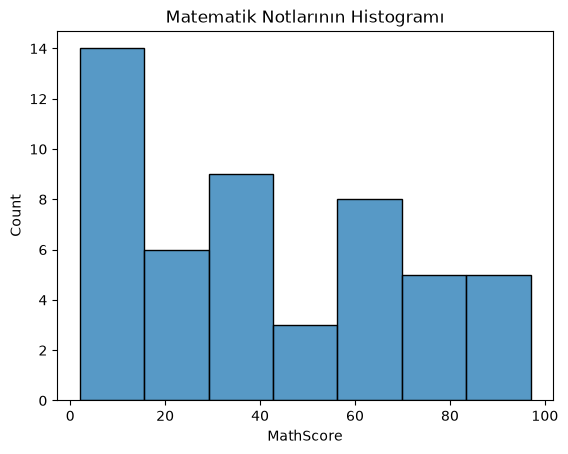

In [29]:
sns.histplot(data=df, x="MathScore")
plt.title("Matematik Notlarının Histogramı")
plt.show() 

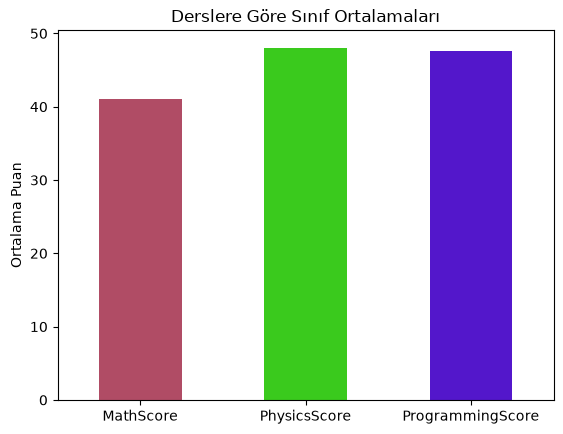

In [30]:

df[['MathScore', 'PhysicsScore', 'ProgrammingScore']].mean().plot(kind='bar', color=["#B04C65", "#3ACA1D", "#5317CB"])

plt.title("Derslere Göre Sınıf Ortalamaları")
plt.ylabel("Ortalama Puan")
plt.xticks(rotation=0)
plt.show()

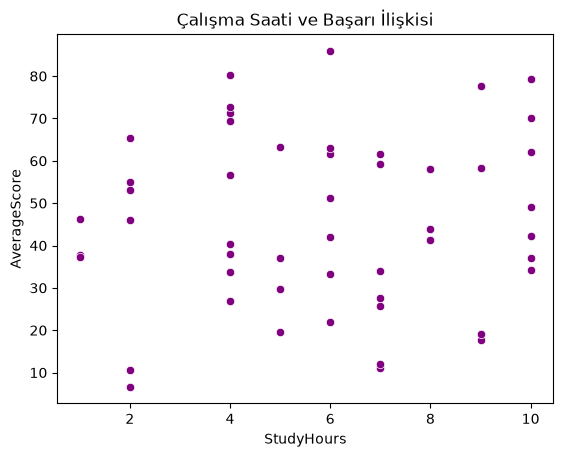

In [35]:
sns.scatterplot(data=df, x="StudyHours", y="AverageScore" , color = "purple")

plt.title("Çalışma Saati ve Başarı İlişkisi")
plt.show()

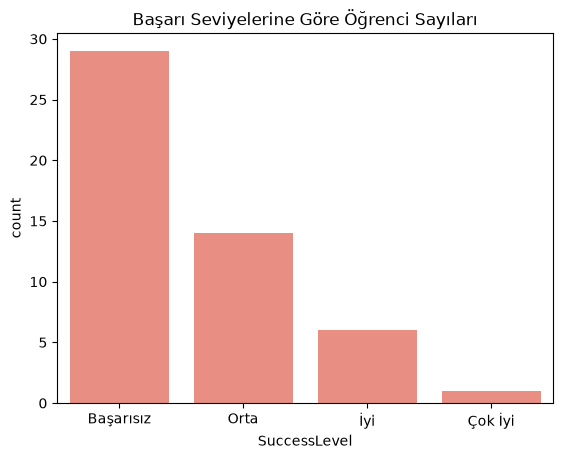

In [34]:
sns.countplot(data=df, x="SuccessLevel", color = "salmon")

plt.title("Başarı Seviyelerine Göre Öğrenci Sayıları")
plt.show()